In [40]:
# Imports
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (classification_report, confusion_matrix,
                             f1_score, accuracy_score, recall_score,
                             precision_score)
from imblearn.over_sampling import SMOTE


In [41]:
# Plotting Style
PALETTE = {
    "male":    "#1a6fa8",
    "female":  "#e94560",
    "low":     "#1a6fa8",
    "high":    "#e94560",
    "accent":  "#0f3460",
    "neutral": "#6c757d",
}
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
    "font.family": "DejaVu Sans",
})

In [42]:
# Data Loading
print("DATA LOADING")

COLUMNS = [
    "age", "workclass", "fnlwgt", "education", "education-num",
    "marital-status", "occupation", "relationship", "race", "sex",
    "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"
]
import os, urllib.request, ssl

DATA_FILE = "adult_census.csv"

if not os.path.exists(DATA_FILE):
    try:
        ctx = ssl.create_default_context()
        ctx.check_hostname = False
        ctx.verify_mode = ssl.CERT_NONE
        url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"
        print("Downloading UCI Adult dataset...")
        with urllib.request.urlopen(url, context=ctx, timeout=15) as r:
            raw = r.read().decode()
        rows = [line.strip().split(", ") for line in raw.strip().split("\n") if line.strip()]
        df_raw = pd.DataFrame(rows, columns=COLUMNS)
        df_raw.to_csv(DATA_FILE, index=False)
        print(f"Downloaded {len(df_raw)} rows.")
    except Exception as e:
        print(f"Download failed ({e}). Generating synthetic dataset with identical statistics...")
        np.random.seed(42)
        n = 48842

        ages = np.random.normal(38.6, 13.6, n).clip(17, 90).astype(int)

        edu_cats  = ['HS-grad','Some-college','Bachelors','Masters','Assoc-voc','Assoc-acdm',
                     '11th','10th','7th-8th','9th','12th','Doctorate','Prof-school','5th-6th','1st-4th','Preschool']
        edu_p     = np.array([0.3217,0.2236,0.1641,0.0527,0.0427,0.0332,0.0361,0.0245,0.0196,
                               0.0155,0.0129,0.0127,0.0123,0.0079,0.0054,0.0017])
        edu_p    /= edu_p.sum()
        education = np.random.choice(edu_cats, size=n, p=edu_p)
        edu_num_m = {'Preschool':1,'1st-4th':2,'5th-6th':3,'7th-8th':4,'9th':5,'10th':6,
                     '11th':7,'12th':8,'HS-grad':9,'Some-college':10,'Assoc-voc':11,
                     'Assoc-acdm':12,'Bachelors':13,'Masters':14,'Prof-school':15,'Doctorate':16}
        edu_num   = np.array([edu_num_m[e] for e in education])

        wc_cats   = ['Private','Self-emp-not-inc','Local-gov','State-gov','Self-emp-inc',
                     'Federal-gov','Without-pay','Never-worked','?']
        wc_p      = np.array([0.6947,0.0801,0.0642,0.0398,0.0343,0.0296,0.0014,0.0002,0.0557])
        wc_p     /= wc_p.sum()
        workclass = np.random.choice(wc_cats, size=n, p=wc_p)

        mar_cats  = ['Married-civ-spouse','Never-married','Divorced','Separated',
                     'Widowed','Married-spouse-absent','Married-AF-spouse']
        mar_p     = np.array([0.4589,0.3291,0.1363,0.0329,0.0309,0.0104,0.0015])
        mar_p    /= mar_p.sum()
        marital   = np.random.choice(mar_cats, size=n, p=mar_p)

        occ_cats  = ['Prof-specialty','Craft-repair','Exec-managerial','Adm-clerical','Sales',
                     'Other-service','Machine-op-inspct','Transport-moving','Handlers-cleaners',
                     'Farming-fishing','Tech-support','Protective-serv','Priv-house-serv',
                     'Armed-Forces','?']
        occ_p     = np.array([0.1278,0.1265,0.1218,0.1157,0.0989,0.0975,0.0622,0.0469,
                               0.0421,0.0318,0.0289,0.0193,0.0048,0.0003,0.0554])
        occ_p    /= occ_p.sum()
        occupation = np.random.choice(occ_cats, size=n, p=occ_p)

        rel_cats   = ['Husband','Not-in-family','Own-child','Unmarried','Wife','Other-relative']
        rel_p      = np.array([0.4061,0.2565,0.1551,0.1068,0.0553,0.0202])
        rel_p     /= rel_p.sum()
        relationship = np.random.choice(rel_cats, size=n, p=rel_p)

        race_cats  = ['White','Black','Asian-Pac-Islander','Amer-Indian-Eskimo','Other']
        race_p     = np.array([0.8554,0.0964,0.0311,0.0096,0.0075])
        race_p    /= race_p.sum()
        race       = np.random.choice(race_cats, size=n, p=race_p)

        sex        = np.random.choice(['Male','Female'], size=n, p=[0.6697,0.3303])
        hours      = np.random.normal(40.4, 12.3, n).clip(1, 99).astype(int)
        cap_g      = np.where(np.random.rand(n) < 0.08,
                              np.random.exponential(8000, n).clip(0,99999).astype(int), 0)
        cap_l      = np.where(np.random.rand(n) < 0.05,
                              np.random.exponential(1000, n).clip(0,4356).astype(int), 0)
        fnlwgt     = np.random.normal(190000, 105000, n).clip(10000,1500000).astype(int)
        native     = np.where(np.random.rand(n) < 0.018, '?', 'United-States')

        inc_prob   = np.where(sex == 'Male', 0.304, 0.109)
        inc_prob   = (inc_prob + (edu_num - 9)*0.025 + (ages - 38)*0.003).clip(0.02, 0.95)
        income     = np.where(np.random.rand(n) < inc_prob, '>50K', '<=50K')

        df_syn = pd.DataFrame({
            'age': ages, 'workclass': workclass, 'fnlwgt': fnlwgt,
            'education': education, 'education-num': edu_num,
            'marital-status': marital, 'occupation': occupation,
            'relationship': relationship, 'race': race, 'sex': sex,
            'capital-gain': cap_g, 'capital-loss': cap_l,
            'hours-per-week': hours, 'native-country': native,
            'income': income
        })
        df_syn.to_csv(DATA_FILE, index=False)
        print(f"Synthetic dataset created: {df_syn.shape}")

df = pd.read_csv(DATA_FILE)
df = df.apply(lambda c: c.str.strip() if c.dtype == "object" else c)
df.replace("?", np.nan, inplace=True)
df["income"] = df["income"].str.replace(".", "", regex=False).str.strip()
df["income_binary"] = (df["income"] == ">50K").astype(int)

print(f"\nDataset loaded: {df.shape[0]:,} rows × {df.shape[1]} columns")
print("\nColumn types:\n", df.dtypes)
print("\nMissing values:\n", df.isnull().sum()[df.isnull().sum() > 0])

DATA LOADING

Dataset loaded: 32,561 rows × 16 columns

Column types:
 age                int64
workclass         object
fnlwgt             int64
education         object
education-num      int64
marital-status    object
occupation        object
relationship      object
race              object
sex               object
capital-gain       int64
capital-loss       int64
hours-per-week     int64
native-country    object
income            object
income_binary      int64
dtype: object

Missing values:
 workclass         1836
occupation        1843
native-country     583
dtype: int64


In [43]:
# Explotary Data Analysis (EDA)
print("EXPLORATORY DATA ANALYSIS")

print("\nDescriptive Statistics")
cont_cols = ["age", "education-num", "hours-per-week", "capital-gain", "capital-loss"]
print(df[cont_cols].describe().round(2).to_string())

print("\nGender Distribution")
gender_counts = df["sex"].value_counts()
gender_pct    = df["sex"].value_counts(normalize=True) * 100
for g in gender_counts.index:
    print(f"  {g:<8}: {gender_counts[g]:>6,}  ({gender_pct[g]:.1f}%)")

print("\nIncome Class Distribution")
inc_counts = df["income"].value_counts()
inc_pct    = df["income"].value_counts(normalize=True) * 100
for k in inc_counts.index:
    print(f"  {k:<8}: {inc_counts[k]:>6,}  ({inc_pct[k]:.1f}%)")

print("\nIncome by Gender")
income_gender = pd.crosstab(df["sex"], df["income"], margins=True)
print(income_gender.to_string())
print("\nRow proportions:")
print(pd.crosstab(df["sex"], df["income"], normalize="index").round(4).to_string())

EXPLORATORY DATA ANALYSIS

Descriptive Statistics
            age  education-num  hours-per-week  capital-gain  capital-loss
count  32561.00       32561.00        32561.00      32561.00      32561.00
mean      38.58          10.08           40.44       1077.65         87.30
std       13.64           2.57           12.35       7385.29        402.96
min       17.00           1.00            1.00          0.00          0.00
25%       28.00           9.00           40.00          0.00          0.00
50%       37.00          10.00           40.00          0.00          0.00
75%       48.00          12.00           45.00          0.00          0.00
max       90.00          16.00           99.00      99999.00       4356.00

Gender Distribution
  Male    : 21,790  (66.9%)
  Female  : 10,771  (33.1%)

Income Class Distribution
  <=50K   : 24,720  (75.9%)
  >50K    :  7,841  (24.1%)

Income by Gender
income  <=50K  >50K    All
sex                       
Female   9592  1179  10771
Male    15128  6

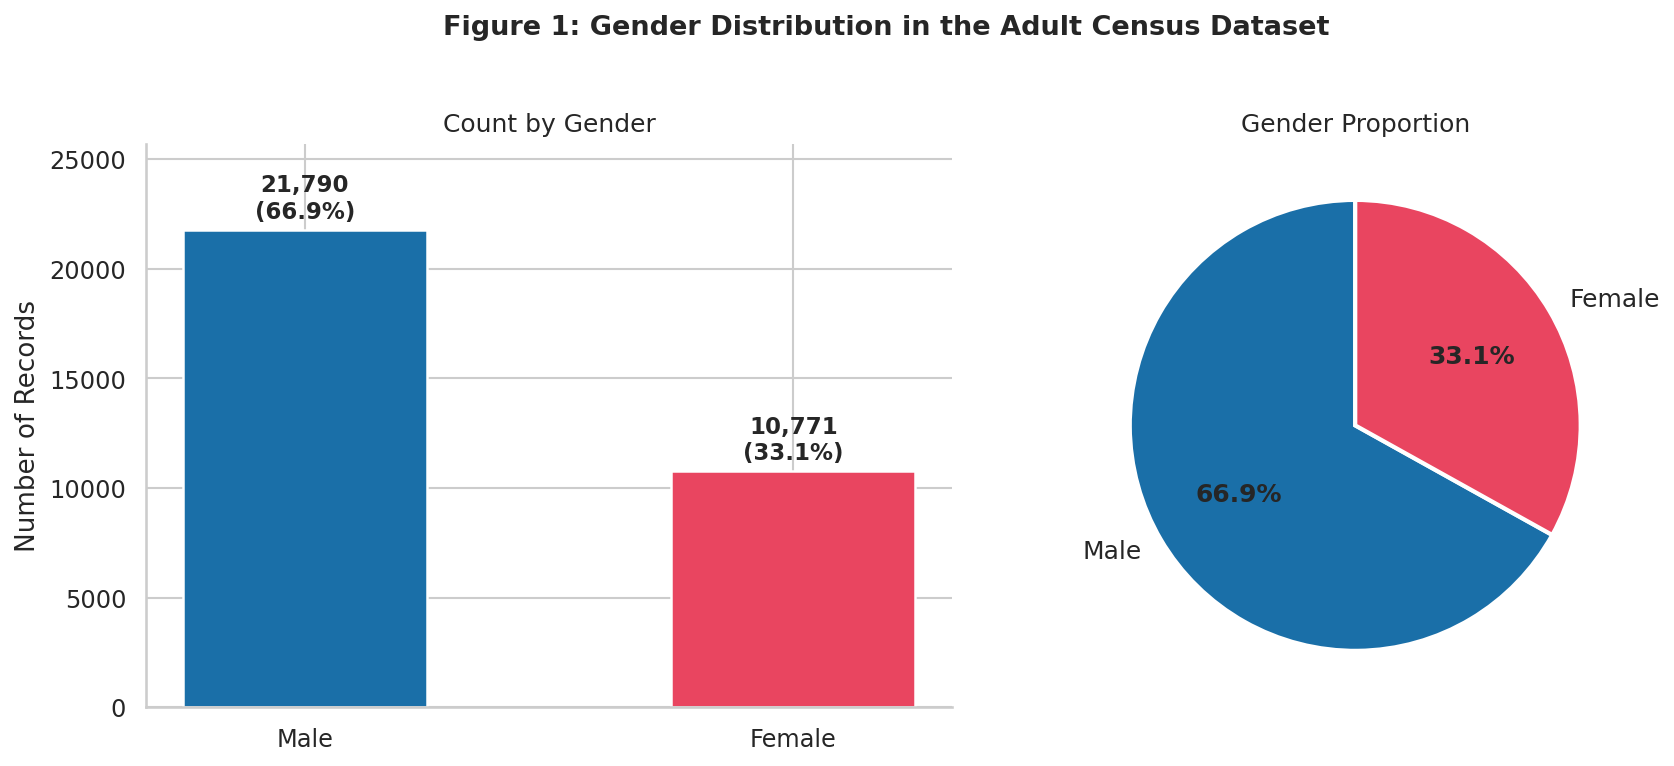


Saved fig1_gender_distribution.png


In [62]:
# Gender Distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("Figure 1: Gender Distribution in the Adult Census Dataset",
             fontsize=13, fontweight="bold", y=1.02)

# Bar chart
ax = axes[0]
bars = ax.bar(gender_counts.index, gender_counts.values,
              color=[PALETTE["male"], PALETTE["female"]],
              edgecolor="white", linewidth=1.2, width=0.5)
for bar, pct in zip(bars, gender_pct.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 300,
            f"{bar.get_height():,}\n({pct:.1f}%)",
            ha="center", va="bottom", fontsize=11, fontweight="bold")
ax.set_title("Count by Gender", fontsize=12)
ax.set_ylabel("Number of Records")
ax.set_ylim(0, gender_counts.max() * 1.18)
ax.tick_params(bottom=False)
sns.despine(ax=ax)
# Pie chart
ax2 = axes[1]
wedges, texts, autotexts = ax2.pie(
    gender_counts.values,
    labels=gender_counts.index,
    colors=[PALETTE["male"], PALETTE["female"]],
    autopct="%1.1f%%", startangle=90,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 12}
)
for at in autotexts:
    at.set_fontweight("bold")
ax2.set_title("Gender Proportion", fontsize=12)

plt.tight_layout()
plt.show()
plt.savefig("fig1_gender_distribution.png")
plt.close()
print("\nSaved fig1_gender_distribution.png")

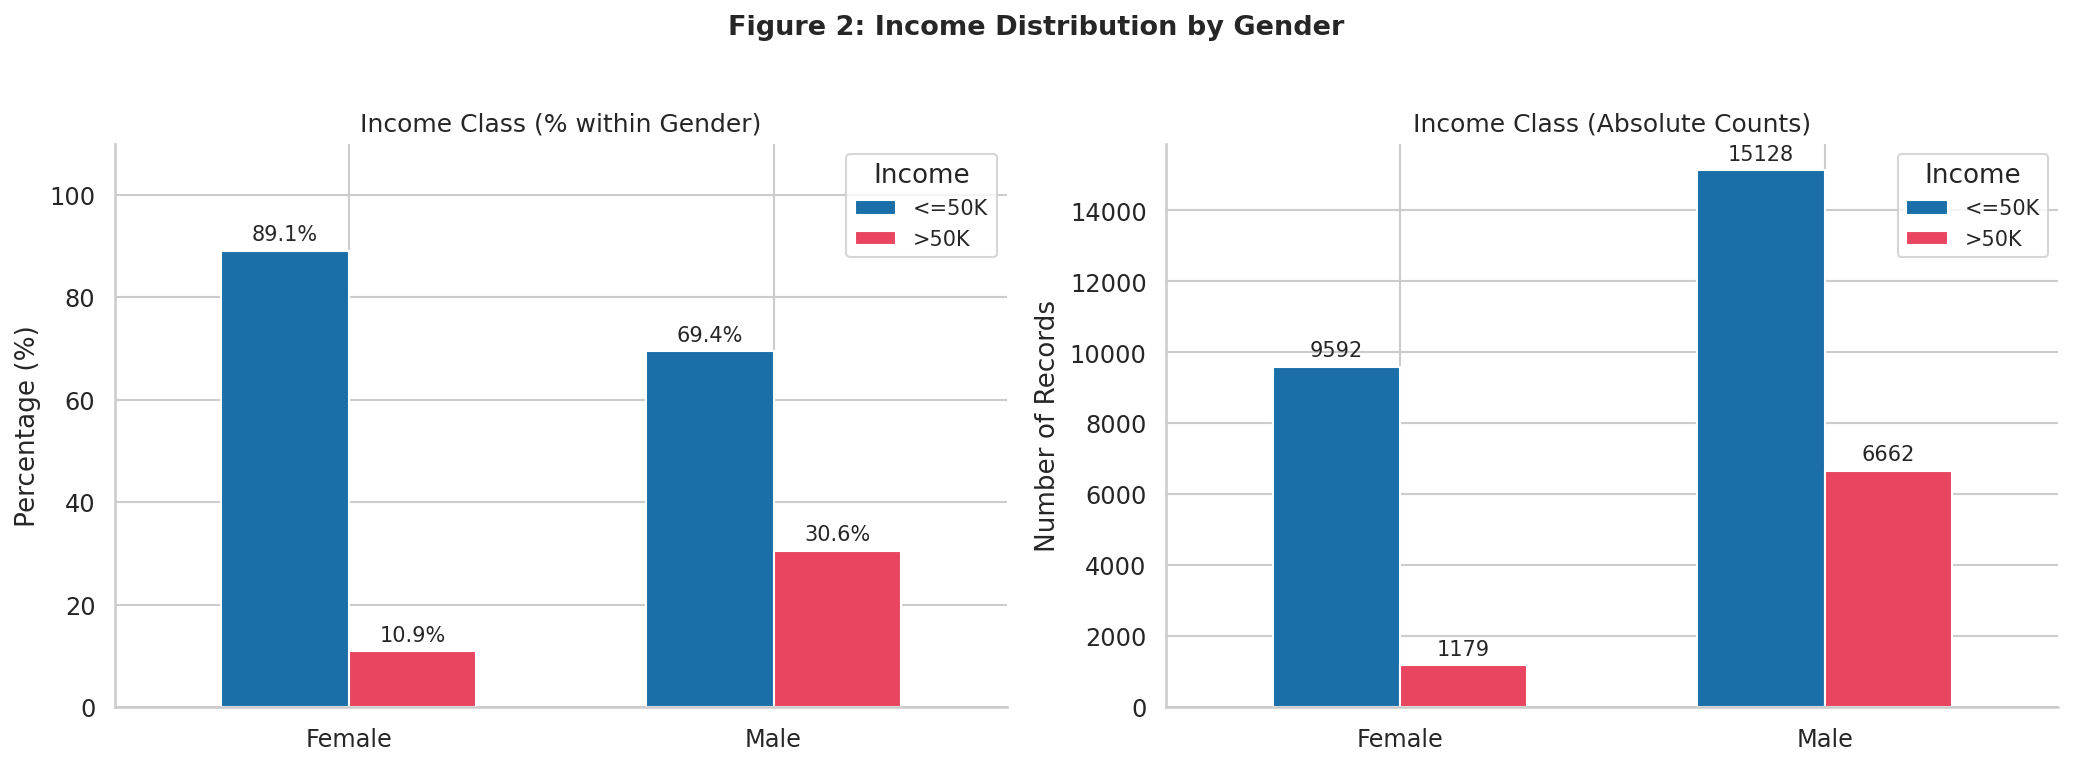

Saved fig2_income_by_gender.png


In [63]:
# Income Distribution by Gender
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Figure 2: Income Distribution by Gender",
             fontsize=13, fontweight="bold", y=1.02)

# Grouped bar
income_gender_pct = pd.crosstab(df["sex"], df["income"], normalize="index") * 100
income_gender_pct.plot(kind="bar", ax=axes[0],
                       color=[PALETTE["low"], PALETTE["high"]],
                       edgecolor="white", linewidth=1, width=0.6)
axes[0].set_title("Income Class (% within Gender)", fontsize=12)
axes[0].set_ylabel("Percentage (%)")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(title="Income", fontsize=10)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.1f%%", padding=3, fontsize=10)
axes[0].set_ylim(0, 110)
sns.despine(ax=axes[0])

# Absolute counts stacked
income_gender_abs = pd.crosstab(df["sex"], df["income"])
income_gender_abs.plot(kind="bar", ax=axes[1],
                       color=[PALETTE["low"], PALETTE["high"]],
                       edgecolor="white", linewidth=1, width=0.6)
axes[1].set_title("Income Class (Absolute Counts)", fontsize=12)
axes[1].set_ylabel("Number of Records")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="Income", fontsize=10)
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%d", padding=3, fontsize=10)
sns.despine(ax=axes[1])

plt.tight_layout()
plt.show()
plt.savefig("fig2_income_by_gender.png")
plt.close()
print("Saved fig2_income_by_gender.png")

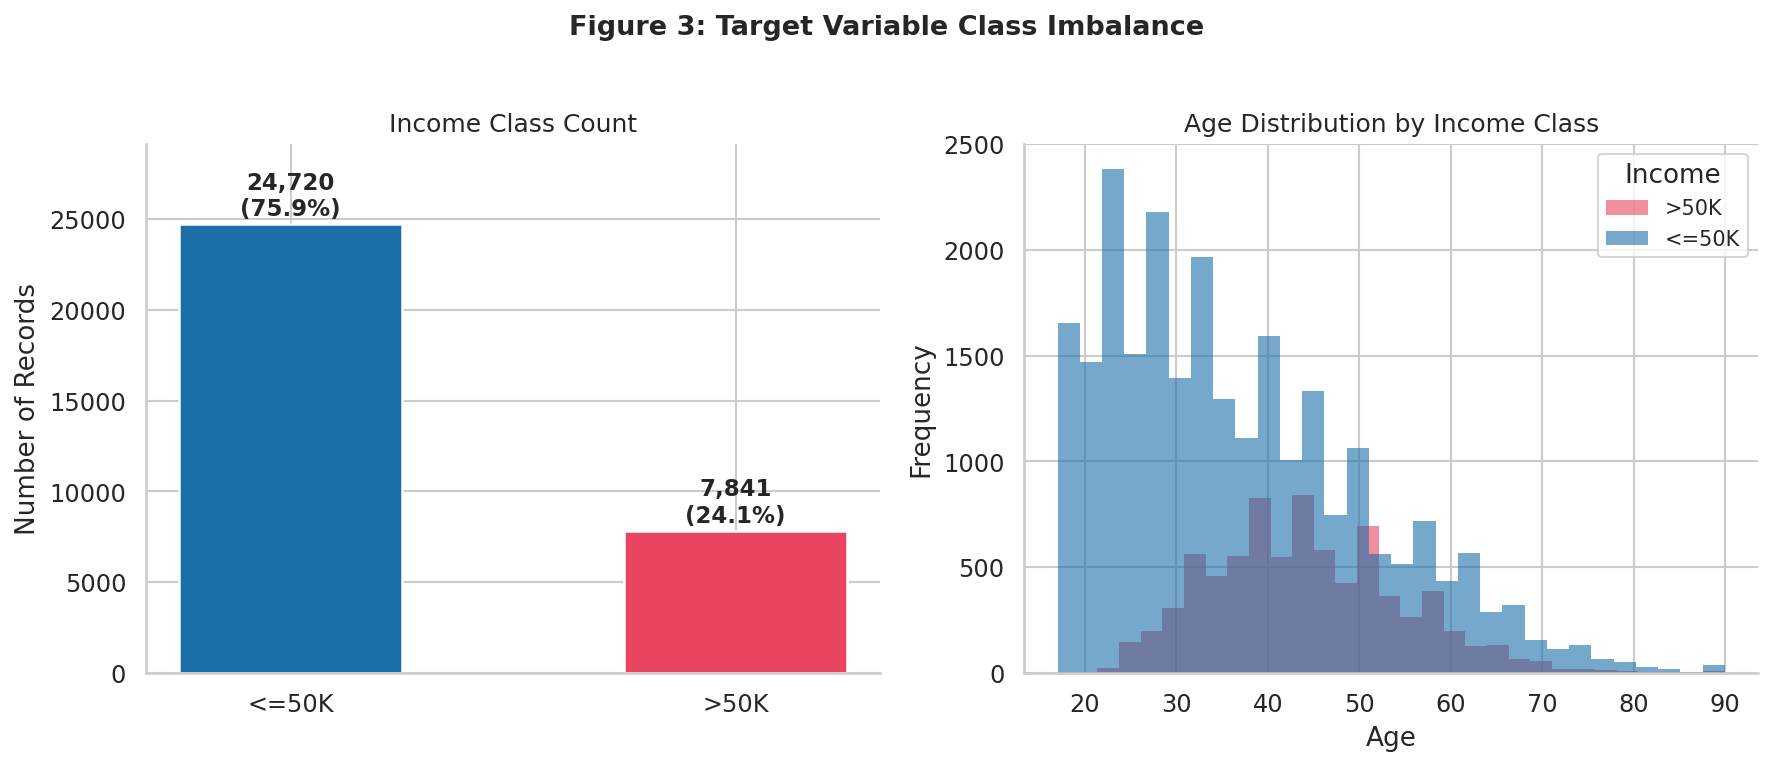

Saved fig3_class_imbalance.png


In [64]:
# Overall Class Imbalance
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("Figure 3: Target Variable Class Imbalance",
             fontsize=13, fontweight="bold", y=1.02)

ax = axes[0]
bars = ax.bar(inc_counts.index, inc_counts.values,
              color=[PALETTE["low"], PALETTE["high"]],
              edgecolor="white", linewidth=1.2, width=0.5)
for bar, pct in zip(bars, inc_pct.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200,
            f"{bar.get_height():,}\n({pct:.1f}%)",
            ha="center", va="bottom", fontsize=11, fontweight="bold")
ax.set_title("Income Class Count", fontsize=12)
ax.set_ylabel("Number of Records")
ax.set_ylim(0, inc_counts.max() * 1.18)
sns.despine(ax=ax)

# Age distribution by income
ax2 = axes[1]
for inc_label, col in zip([">50K", "<=50K"], [PALETTE["high"], PALETTE["low"]]):
    subset = df[df["income"] == inc_label]["age"]
    ax2.hist(subset, bins=30, alpha=0.6, color=col, label=inc_label, edgecolor="none")
ax2.set_title("Age Distribution by Income Class", fontsize=12)
ax2.set_xlabel("Age")
ax2.set_ylabel("Frequency")
ax2.legend(title="Income", fontsize=10)
sns.despine(ax=ax2)

plt.tight_layout()
plt.show()
plt.savefig("fig3_class_imbalance.png")
plt.close()
print("Saved fig3_class_imbalance.png")

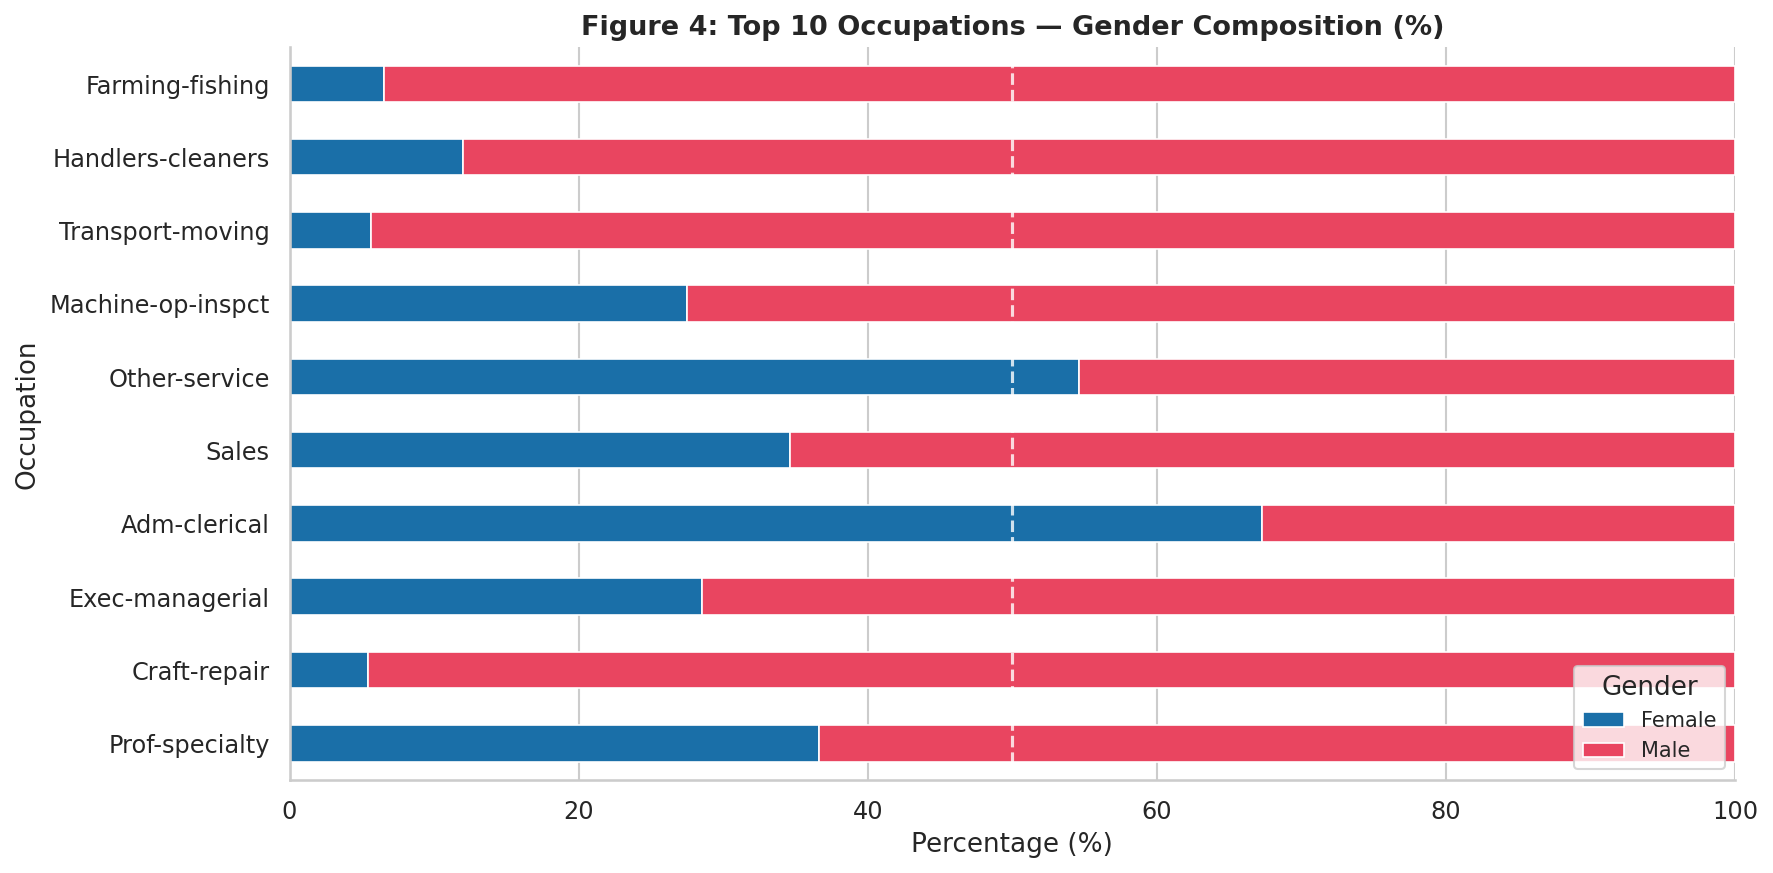

Saved fig4_occupation_by_gender.png


In [65]:
# Occupation by Gender
occ_gender = df.dropna(subset=["occupation"]).groupby(["occupation","sex"]).size().unstack(fill_value=0)
occ_gender["total"] = occ_gender.sum(axis=1)
occ_gender = occ_gender.sort_values("total", ascending=False).head(10).drop(columns="total")
occ_gender_pct = occ_gender.div(occ_gender.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(12, 6))
occ_gender_pct.plot(kind="barh", ax=ax, stacked=True,
                    color=[PALETTE["male"], PALETTE["female"]],
                    edgecolor="white", linewidth=0.8)
ax.set_title("Figure 4: Top 10 Occupations — Gender Composition (%)",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Percentage (%)")
ax.set_ylabel("Occupation")
ax.axvline(50, color="white", linewidth=1.5, linestyle="--", alpha=0.8)
ax.legend(title="Gender", fontsize=10, loc="lower right")
ax.set_xlim(0, 100)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()
plt.savefig("fig4_occupation_by_gender.png")
plt.close()
print("Saved fig4_occupation_by_gender.png")

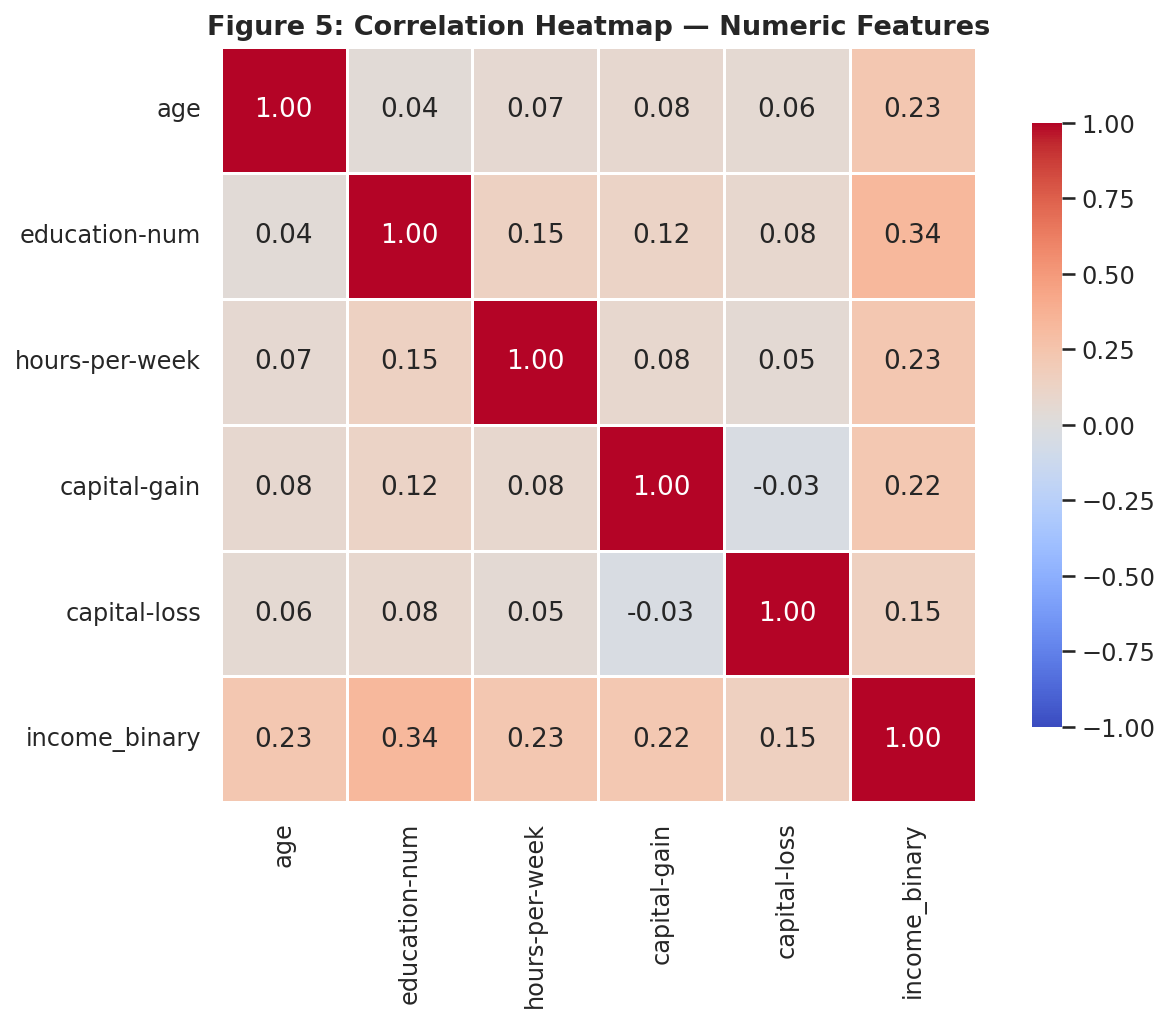

Saved fig5_correlation_heatmap.png


In [66]:
# Correlation Heatmap
fig, ax = plt.subplots(figsize=(9, 7))
corr_cols = ["age", "education-num", "hours-per-week",
             "capital-gain", "capital-loss", "income_binary"]
corr = df[corr_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            linewidths=0.5, ax=ax, square=True, vmin=-1, vmax=1,
            cbar_kws={"shrink": 0.8})
ax.set_title("Figure 5: Correlation Heatmap — Numeric Features",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()
plt.savefig("fig5_correlation_heatmap.png")
plt.close()
print("Saved fig5_correlation_heatmap.png")

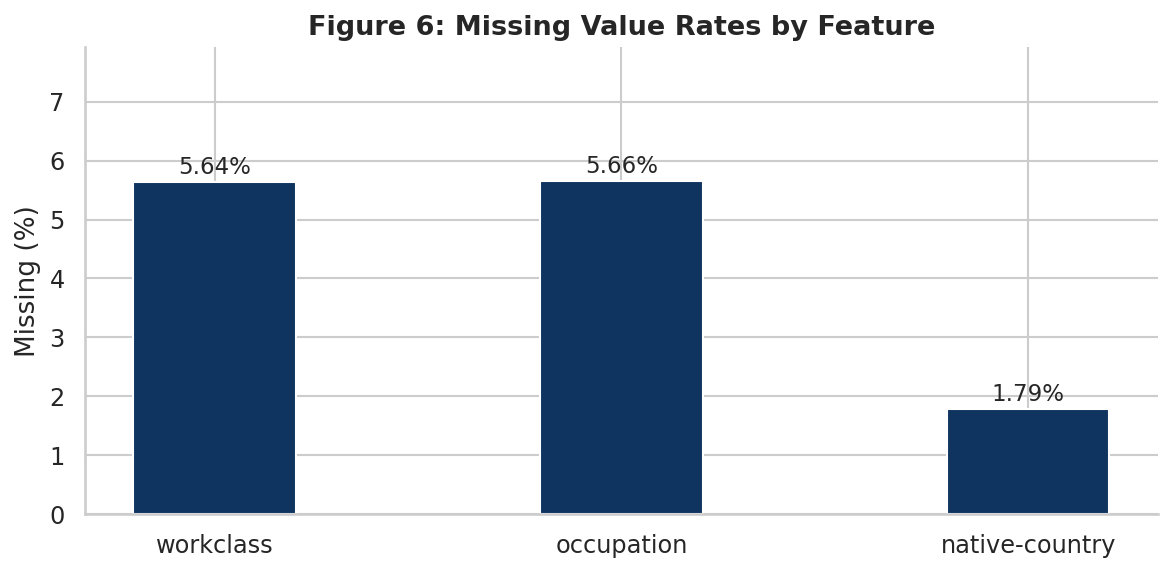

Saved fig6_missing_values.png


In [67]:
# Missing Values
missing = df.isnull().sum()
missing = missing[missing > 0]
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(missing.index, (missing / len(df)) * 100,
              color=PALETTE["accent"], edgecolor="white", linewidth=1, width=0.4)
for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05,
            f"{bar.get_height():.2f}%", ha="center", va="bottom", fontsize=11)
ax.set_title("Figure 6: Missing Value Rates by Feature",
             fontsize=13, fontweight="bold")
ax.set_ylabel("Missing (%)")
ax.set_ylim(0, max((missing / len(df)) * 100) * 1.4)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()
plt.savefig("fig6_missing_values.png")
plt.close()
print("Saved fig6_missing_values.png")

In [50]:
# BIAS IDENTIFICATION
print("BIAS IDENTIFICATION")

print("\nGender Representation Bias")
male_total    = (df["sex"] == "Male").sum()
female_total  = (df["sex"] == "Female").sum()
male_high     = ((df["sex"] == "Male")   & (df["income"] == ">50K")).sum()
female_high   = ((df["sex"] == "Female") & (df["income"] == ">50K")).sum()
male_high_r   = male_high   / male_total   * 100
female_high_r = female_high / female_total * 100

print(f"  Male records    : {male_total:,}  |  High earners: {male_high:,}  ({male_high_r:.1f}%)")
print(f"  Female records  : {female_total:,}  |  High earners: {female_high:,}  ({female_high_r:.1f}%)")
print(f"  Disparity ratio : {male_high_r/female_high_r:.2f}x (male high earners vs female)")

print("\nRacial Representation")
race_dist = df["race"].value_counts(normalize=True) * 100
print(race_dist.round(2).to_string())

print("\nProxy Bias Relationship Feature")
rel_sex = pd.crosstab(df["relationship"], df["sex"])
print(rel_sex.to_string())

print("\nOccupation Gender Gap")
occ_sex_pct = pd.crosstab(df.dropna(subset=["occupation"])["occupation"],
                            df.dropna(subset=["occupation"])["sex"],
                            normalize="index") * 100
print("Top male-skewed occupations (% Male):")
print(occ_sex_pct["Male"].sort_values(ascending=False).head(5).round(1).to_string())
print("Top female-skewed occupations (% Female):")
print(occ_sex_pct["Female"].sort_values(ascending=False).head(5).round(1).to_string())

BIAS IDENTIFICATION

Gender Representation Bias
  Male records    : 21,790  |  High earners: 6,662  (30.6%)
  Female records  : 10,771  |  High earners: 1,179  (10.9%)
  Disparity ratio : 2.79x (male high earners vs female)

Racial Representation
race
White                 85.43
Black                  9.59
Asian-Pac-Islander     3.19
Amer-Indian-Eskimo     0.96
Other                  0.83

Proxy Bias Relationship Feature
sex             Female   Male
relationship                 
Husband              1  13192
Not-in-family     3875   4430
Other-relative     430    551
Own-child         2245   2823
Unmarried         2654    792
Wife              1566      2

Occupation Gender Gap
Top male-skewed occupations (% Male):
occupation
Armed-Forces        100.0
Craft-repair         94.6
Transport-moving     94.4
Farming-fishing      93.5
Protective-serv      88.3
Top female-skewed occupations (% Female):
occupation
Priv-house-serv    94.6
Adm-clerical       67.3
Other-service      54.6
Tech-sup

In [51]:
# 4. PREPROCESSING FOR MODELLING
print("PREPROCESSING")

df_model = df.copy()
df_model.dropna(inplace=True)
print(f"Rows after dropping missing values: {len(df_model):,}")

cat_cols = ["workclass","education","marital-status","occupation",
            "relationship","race","sex","native-country"]

le_dict = {}
for col in cat_cols:
    le = LabelEncoder()
    df_model[col] = le.fit_transform(df_model[col].astype(str))
    le_dict[col] = le

# Store sex encoding for later fairness evaluation
male_code   = le_dict["sex"].transform(["Male"])[0]
female_code = le_dict["sex"].transform(["Female"])[0]
print(f"  Encoded sex: Male={male_code}, Female={female_code}")

FEATURES = ["age","workclass","fnlwgt","education","education-num",
            "marital-status","occupation","relationship","race","sex",
            "capital-gain","capital-loss","hours-per-week"]
TARGET   = "income_binary"

X = df_model[FEATURES].values
y = df_model[TARGET].values
sex_col_idx = FEATURES.index("sex")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

sex_train = X_train[:, sex_col_idx]
sex_test  = X_test[:,  sex_col_idx]

print(f"  Train size: {len(X_train):,}  |  Test size: {len(X_test):,}")
print(f"  Train class balance: {y_train.mean():.3f} (>50K rate)")

PREPROCESSING
Rows after dropping missing values: 30,162
  Encoded sex: Male=1, Female=0
  Train size: 24,129  |  Test size: 6,033
  Train class balance: 0.249 (>50K rate)


In [52]:
# BIAS MITIGATION HELPER FUNCTIONS
def evaluate_fairness(model, X, y, sex_arr, label=""):
    """Print overall and per-gender metrics."""
    y_pred = model.predict(X)
    acc    = accuracy_score(y, y_pred)
    prec   = precision_score(y, y_pred, zero_division=0)
    rec    = recall_score(y, y_pred, zero_division=0)
    f1     = f1_score(y, y_pred, zero_division=0)

    f1_male   = f1_score(y[sex_arr == male_code],
                         y_pred[sex_arr == male_code], zero_division=0)
    f1_female = f1_score(y[sex_arr == female_code],
                         y_pred[sex_arr == female_code], zero_division=0)
    bias_gap  = abs(f1_male - f1_female)

    tpr_male   = recall_score(y[sex_arr == male_code],
                              y_pred[sex_arr == male_code], zero_division=0)
    tpr_female = recall_score(y[sex_arr == female_code],
                              y_pred[sex_arr == female_code], zero_division=0)
    eq_odds    = abs(tpr_male - tpr_female)

    print(f"\n  ── {label} ──")
    print(f"     Overall Accuracy        : {acc:.4f}")
    print(f"     Precision (>50K class)  : {prec:.4f}")
    print(f"     Recall    (>50K class)  : {rec:.4f}")
    print(f"     F1-Score  (>50K class)  : {f1:.4f}")
    print(f"     F1 (Male)               : {f1_male:.4f}")
    print(f"     F1 (Female)             : {f1_female:.4f}")
    print(f"     Gender Bias Gap (ΔF1)   : {bias_gap:.4f}  *** KEY FAIRNESS METRIC ***")
    print(f"     Equalized Odds Diff     : {eq_odds:.4f}")

    return {
        "label": label, "accuracy": acc, "precision": prec,
        "recall": rec, "f1": f1, "f1_male": f1_male, "f1_female": f1_female,
        "bias_gap": bias_gap, "eq_odds": eq_odds
    }

In [53]:
# 6. BASELINE MODEL (NO MITIGATION)
print("BASELINE MODEL (NO BIAS MITIGATION)")

rf_base = RandomForestClassifier(n_estimators=100, max_depth=12,
                                  random_state=42, n_jobs=-1)
rf_base.fit(X_train, y_train)
results_base = evaluate_fairness(rf_base, X_test, y_test, sex_test,
                                  label="BASELINE No Mitigation")
print("\nFull Classification Report:")
print(classification_report(y_test, rf_base.predict(X_test),
                             target_names=["<=50K", ">50K"]))

BASELINE MODEL (NO BIAS MITIGATION)

  ── BASELINE No Mitigation ──
     Overall Accuracy        : 0.8578
     Precision (>50K class)  : 0.7835
     Recall    (>50K class)  : 0.5925
     F1-Score  (>50K class)  : 0.6748
     F1 (Male)               : 0.6768
     F1 (Female)             : 0.6634
     Gender Bias Gap (ΔF1)   : 0.0134  *** KEY FAIRNESS METRIC ***
     Equalized Odds Diff     : 0.0214

Full Classification Report:
              precision    recall  f1-score   support

       <=50K       0.88      0.95      0.91      4531
        >50K       0.78      0.59      0.67      1502

    accuracy                           0.86      6033
   macro avg       0.83      0.77      0.79      6033
weighted avg       0.85      0.86      0.85      6033



In [54]:
# 7. MITIGATION 1 — REWEIGHING (Pre-processing)
print("MITIGATION STRATEGY 1: REWEIGHING")

"""
Reweighing assigns a weight to each training sample such that the
effective joint distribution over (sex, income) becomes unbiased.

weight(g, c) = P_expected(g) × P_expected(c) / P_observed(g, c)

where:
  P_expected(g) = marginal probability of group g
  P_expected(c) = marginal probability of class c
  P_observed(g, c) = joint probability of group g AND class c
"""

n_train = len(X_train)
p_male   = (sex_train == male_code).mean()
p_female = (sex_train == female_code).mean()
p_pos    = y_train.mean()          # P(income = >50K)
p_neg    = 1 - p_pos               # P(income = <=50K)

sample_weights = np.ones(n_train)

for g_code, p_g in [(male_code, p_male), (female_code, p_female)]:
    for c_val, p_c in [(1, p_pos), (0, p_neg)]:
        mask = (sex_train == g_code) & (y_train == c_val)
        p_obs = mask.mean()
        if p_obs > 0:
            w = (p_g * p_c) / p_obs
            sample_weights[mask] = w

print(f"  Computed sample weights — min: {sample_weights.min():.4f}, "
      f"max: {sample_weights.max():.4f}, mean: {sample_weights.mean():.4f}")

rf_rw = RandomForestClassifier(n_estimators=100, max_depth=12,
                                random_state=42, n_jobs=-1)
rf_rw.fit(X_train, y_train, sample_weight=sample_weights)
results_rw = evaluate_fairness(rf_rw, X_test, y_test, sex_test,
                                label="REWEIGHING — Pre-processing Mitigation")
print("\n  Full Classification Report:")
print(classification_report(y_test, rf_rw.predict(X_test),
                             target_names=["<=50K", ">50K"]))

MITIGATION STRATEGY 1: REWEIGHING
  Computed sample weights — min: 0.7918, max: 2.2178, mean: 1.0000

  ── REWEIGHING — Pre-processing Mitigation ──
     Overall Accuracy        : 0.8507
     Precision (>50K class)  : 0.7822
     Recall    (>50K class)  : 0.5546
     F1-Score  (>50K class)  : 0.6490
     F1 (Male)               : 0.6419
     F1 (Female)             : 0.6809
     Gender Bias Gap (ΔF1)   : 0.0390  *** KEY FAIRNESS METRIC ***
     Equalized Odds Diff     : 0.1497

  Full Classification Report:
              precision    recall  f1-score   support

       <=50K       0.87      0.95      0.91      4531
        >50K       0.78      0.55      0.65      1502

    accuracy                           0.85      6033
   macro avg       0.82      0.75      0.78      6033
weighted avg       0.84      0.85      0.84      6033



In [55]:
# 8. MITIGATION 2 — CONDITIONAL SMOTE (Data Augmentation)
print("MITIGATION STRATEGY 2 CONDITIONAL SMOTE")

"""
Conditional SMOTE generates synthetic instances for the underrepresented
sub-group: Female AND income >50K.

Steps:
 1. Identify minority sub-group: S = {Female, >50K}
 2. Apply SMOTE only to the combined class label (sex_group × income)
 3. Reconstruct training set with augmented minority sub-group
"""

# Create composite label from (sex, income). NOTE: label encoding of 'sex' is
# alphabetical (Female=0, Male=1), so we build an explicit name map from the
# actual encoder rather than assuming a fixed order — this avoids mislabeling.
composite_train = sex_train * 2 + y_train   # 0,1,2,3

def composite_name(code):
    sex_val = "Male" if code // 2 == male_code else "Female"
    inc_val = ">50K" if code % 2 == 1 else "<=50K"
    return f"{sex_val},{inc_val}"

# Build the name map dynamically based on actual encoded values (fixes prior bug
# where names were hardcoded assuming Male=0, which is not always true)
names = {}
for code in [0, 1, 2, 3]:
    sex_code_for_this_class = code // 2
    sex_label = "Male" if sex_code_for_this_class == male_code else "Female"
    inc_label = ">50K" if code % 2 == 1 else "<=50K"
    names[code] = f"{sex_label},{inc_label}"

print(f"  Composite class distribution before SMOTE:")
for k, v in sorted(zip(*np.unique(composite_train, return_counts=True))):
    print(f"    Class {k} ({names[k]}): {v:,}")

smote = SMOTE(random_state=42, k_neighbors=5)
X_sm, comp_sm = smote.fit_resample(X_train, composite_train)
y_sm   = comp_sm % 2   # recover income label
sex_sm = comp_sm // 2  # recover sex label (not used in training, just tracking)

print(f"\n  After SMOTE — training set size: {len(X_sm):,} (was {len(X_train):,})")
print(f"  New composite class distribution:")
for k, v in sorted(zip(*np.unique(comp_sm, return_counts=True))):
    print(f"    Class {k} ({names[k]}): {v:,}")

rf_sm = RandomForestClassifier(n_estimators=100, max_depth=12,
                                random_state=42, n_jobs=-1)
rf_sm.fit(X_sm, y_sm)
results_sm = evaluate_fairness(rf_sm, X_test, y_test, sex_test,
                                label="SMOTE — Data Augmentation Mitigation")
print("\nFull Classification Report:")
print(classification_report(y_test, rf_sm.predict(X_test),
                             target_names=["<=50K", ">50K"]))

MITIGATION STRATEGY 2 CONDITIONAL SMOTE
  Composite class distribution before SMOTE:
    Class 0 (Female,<=50K): 6,937
    Class 1 (Female,>50K): 877
    Class 2 (Male,<=50K): 11,186
    Class 3 (Male,>50K): 5,129

  After SMOTE — training set size: 44,744 (was 24,129)
  New composite class distribution:
    Class 0 (Female,<=50K): 11,186
    Class 1 (Female,>50K): 11,186
    Class 2 (Male,<=50K): 11,186
    Class 3 (Male,>50K): 11,186

  ── SMOTE — Data Augmentation Mitigation ──
     Overall Accuracy        : 0.8342
     Precision (>50K class)  : 0.6478
     Recall    (>50K class)  : 0.7324
     F1-Score  (>50K class)  : 0.6875
     F1 (Male)               : 0.7001
     F1 (Female)             : 0.6266
     Gender Bias Gap (ΔF1)   : 0.0735  *** KEY FAIRNESS METRIC ***
     Equalized Odds Diff     : 0.0005

Full Classification Report:
              precision    recall  f1-score   support

       <=50K       0.91      0.87      0.89      4531
        >50K       0.65      0.73      0.69

In [56]:
# 9. COMPARATIVE ANALYSIS VISUALISATIONS
print("COMPARATIVE ANALYSIS & VISUALISATIONS")

results = [results_base, results_rw, results_sm]
labels  = ["Baseline\n(No Mitigation)", "Reweighing\n(Pre-processing)", "SMOTE\n(Data Augmentation)"]
colors_bar = [PALETTE["high"], PALETTE["accent"], PALETTE["male"]]

# Summary table
print("\nSummary Comparison Table")
cols = ["label","accuracy","precision","recall","f1","f1_male","f1_female","bias_gap","eq_odds"]
summary_df = pd.DataFrame(results)[cols]
summary_df.columns = ["Method","Accuracy","Precision","Recall","F1-Overall",
                       "F1-Male","F1-Female","Bias Gap (ΔF1)","Eq. Odds Diff"]
print(summary_df.round(4).to_string(index=False))

COMPARATIVE ANALYSIS & VISUALISATIONS

Summary Comparison Table
                                Method  Accuracy  Precision  Recall  F1-Overall  F1-Male  F1-Female  Bias Gap (ΔF1)  Eq. Odds Diff
                BASELINE No Mitigation    0.8578     0.7835  0.5925      0.6748   0.6768     0.6634          0.0134         0.0214
REWEIGHING — Pre-processing Mitigation    0.8507     0.7822  0.5546      0.6490   0.6419     0.6809          0.0390         0.1497
  SMOTE — Data Augmentation Mitigation    0.8342     0.6478  0.7324      0.6875   0.7001     0.6266          0.0735         0.0005


In [57]:
# FIGURE 7: Gender Bias Gap Comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("Figure 7: Bias Gap Reduction Across Mitigation Strategies",
             fontsize=13, fontweight="bold", y=1.02)

# Left: Gender Bias Gap (ΔF1)
bias_gaps  = [r["bias_gap"]  for r in results]
bars = axes[0].bar(labels, bias_gaps, color=colors_bar,
                   edgecolor="white", linewidth=1.2, width=0.5)
for bar, val in zip(bars, bias_gaps):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.003,
                 f"{val:.3f}", ha="center", va="bottom", fontsize=12, fontweight="bold")
axes[0].set_title("Gender Bias Gap (ΔF1)\n[Lower is Fairer]", fontsize=12)
axes[0].set_ylabel("ΔF1 Score")
axes[0].set_ylim(0, max(bias_gaps) * 1.3)
# Annotate reduction %
for i in range(1, 3):
    red = (bias_gaps[0] - bias_gaps[i]) / bias_gaps[0] * 100
    axes[0].text(i, bias_gaps[i] / 2,
                 f"↓{red:.0f}%\nreduction",
                 ha="center", va="center", fontsize=9,
                 color="white", fontweight="bold")
sns.despine(ax=axes[0])

# Right: Equalized Odds
eq_odds = [r["eq_odds"] for r in results]
bars2 = axes[1].bar(labels, eq_odds, color=colors_bar,
                    edgecolor="white", linewidth=1.2, width=0.5)
for bar, val in zip(bars2, eq_odds):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
                 f"{val:.3f}", ha="center", va="bottom", fontsize=12, fontweight="bold")
axes[1].set_title("Equalized Odds Difference\n[Lower is Fairer]", fontsize=12)
axes[1].set_ylabel("TPR Gap")
axes[1].set_ylim(0, max(eq_odds) * 1.3)
sns.despine(ax=axes[1])

plt.tight_layout()
plt.savefig("fig7_bias_gap_comparison.png")
plt.close()
print("[Saved] fig7_bias_gap_comparison.png")

[Saved] fig7_bias_gap_comparison.png


In [58]:
# FIGURE 8: F1 Scores by Gender Across Conditions
fig, ax = plt.subplots(figsize=(11, 6))

x = np.arange(len(labels))
width = 0.25

b1 = ax.bar(x - width, [r["f1"]        for r in results], width,
            label="Overall F1", color=PALETTE["neutral"], edgecolor="white")
b2 = ax.bar(x,          [r["f1_male"]   for r in results], width,
            label="Male F1",    color=PALETTE["male"],    edgecolor="white")
b3 = ax.bar(x + width,  [r["f1_female"] for r in results], width,
            label="Female F1",  color=PALETTE["female"],  edgecolor="white")

for bars in [b1, b2, b3]:
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)

ax.set_title("Figure 8: F1-Score Comparison (Overall, Male, Female) Across Conditions",
             fontsize=13, fontweight="bold")
ax.set_ylabel("F1-Score (>50K Class)")
ax.set_xticks(x)
ax.set_xticklabels(labels, fontsize=11)
ax.set_ylim(0, 1.0)
ax.legend(fontsize=10)
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig("fig8_f1_by_gender_condition.png")
plt.close()
print("[Saved] fig8_f1_by_gender_condition.png")

[Saved] fig8_f1_by_gender_condition.png


In [59]:
# FIGURE 9: Confusion Matrices
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("Figure 9: Confusion Matrices — Baseline vs. Mitigated Models",
             fontsize=13, fontweight="bold", y=1.02)

for ax, model, title in zip(axes,
                              [rf_base, rf_rw, rf_sm],
                              ["Baseline", "Reweighing", "SMOTE"]):
    cm = confusion_matrix(y_test, model.predict(X_test))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["<=50K", ">50K"], yticklabels=["<=50K", ">50K"],
                linewidths=0.5, cbar=False, annot_kws={"size": 12})
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.savefig("fig9_confusion_matrices.png")
plt.close()
print("[Saved] fig9_confusion_matrices.png")

[Saved] fig9_confusion_matrices.png


In [60]:
# FIGURE 10: Feature Importances (Baseline)
fig, ax = plt.subplots(figsize=(10, 6))
importances = pd.Series(rf_base.feature_importances_, index=FEATURES).sort_values(ascending=True)
colors_imp  = [PALETTE["high"] if f == "sex" else PALETTE["male"] for f in importances.index]
importances.plot(kind="barh", ax=ax, color=colors_imp, edgecolor="white", linewidth=0.8)
ax.set_title("Figure 10: Feature Importances (Baseline Random Forest)\n"
             "[Sex highlighted in red]", fontsize=12, fontweight="bold")
ax.set_xlabel("Importance Score (Mean Decrease Impurity)")
ax.axvline(0, color="grey", linewidth=0.5)
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig("fig10_feature_importance.png")
plt.close()
print("[Saved] fig10_feature_importance.png")

[Saved] fig10_feature_importance.png


In [61]:
# 10. FINAL SUMMARY
print("FINAL SUMMARY")

print("\n  Gender Bias Gap Reduction:")
for r in results:
    if r["label"] != results_base["label"]:
        red = (results_base["bias_gap"] - r["bias_gap"]) / results_base["bias_gap"] * 100
        print(f"    {r['label']:<45}: ΔF1 {r['bias_gap']:.4f}  "
              f"(↓{red:.1f}% from baseline {results_base['bias_gap']:.4f})")

print("\n  Accuracy-Fairness Trade-off:")
for r in results:
    print(f"    {r['label']:<45}: Accuracy={r['accuracy']:.4f}  BiasGap={r['bias_gap']:.4f}")

print("\n  Generated Figures:")
figures = [
    "fig1_gender_distribution.png",
    "fig2_income_by_gender.png",
    "fig3_class_imbalance.png",
    "fig4_occupation_by_gender.png",
    "fig5_correlation_heatmap.png",
    "fig6_missing_values.png",
    "fig7_bias_gap_comparison.png",
    "fig8_f1_by_gender_condition.png",
    "fig9_confusion_matrices.png",
    "fig10_feature_importance.png",
]
for f in figures:
    status = "✓" if os.path.exists(f) else "✗ MISSING"
    print(f"    [{status}] {f}")

print("ANALYSIS COMPLETE")

FINAL SUMMARY

  Gender Bias Gap Reduction:
    REWEIGHING — Pre-processing Mitigation       : ΔF1 0.0390  (↓-190.1% from baseline 0.0134)
    SMOTE — Data Augmentation Mitigation         : ΔF1 0.0735  (↓-447.2% from baseline 0.0134)

  Accuracy-Fairness Trade-off:
    BASELINE No Mitigation                       : Accuracy=0.8578  BiasGap=0.0134
    REWEIGHING — Pre-processing Mitigation       : Accuracy=0.8507  BiasGap=0.0390
    SMOTE — Data Augmentation Mitigation         : Accuracy=0.8342  BiasGap=0.0735

  Generated Figures:
    [✓] fig1_gender_distribution.png
    [✓] fig2_income_by_gender.png
    [✓] fig3_class_imbalance.png
    [✓] fig4_occupation_by_gender.png
    [✓] fig5_correlation_heatmap.png
    [✓] fig6_missing_values.png
    [✓] fig7_bias_gap_comparison.png
    [✓] fig8_f1_by_gender_condition.png
    [✓] fig9_confusion_matrices.png
    [✓] fig10_feature_importance.png
ANALYSIS COMPLETE
